# Numerical option pricing: from trees to learned exercise policies

**C++17 pricing engines · Python analysis · European and American vanilla options · No dividends**

This notebook investigates three questions:

1. How do CRR tree prices and Monte Carlo estimates converge toward their references?
2. How much do antithetic variates, a stock control variate, and importance sampling reduce estimator variance?
3. How do a prescribed exercise rule and a learned Longstaff–Schwartz rule compare for an American put?

All option prices below are calculated by the six C++ executables. Python reads their CSV output,
calculates summary statistics, and displays figures. The stock model is risk-neutral geometric Brownian
motion, $dS_t=rS_tdt+\sigma S_tdW_t$, with $q=0$.

Run `python scripts/build.py`, `python scripts/run_experiments.py --quick`, and
`python scripts/plot_results.py` from the repository root before running all cells.
The committed figures and executed outputs allow this notebook to be reviewed without a local compiler.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Open the notebook from the repository or notebooks directory.'
sys.path.insert(0, str(ROOT / 'scripts'))
from run_experiments import run

DATA = ROOT / 'data' / 'experiments'
manifest = json.loads((DATA / 'manifest.json').read_text(encoding='utf-8'))
frames = {name: pd.read_csv(DATA / f'{name}.csv') for name in
          ['tree_convergence', 'mc_convergence', 'variance_reduction',
           'american_convergence', 'exercise_grid', 'newton_convergence', 'variance_summary']}
print('Profile:', manifest['profile'], '| Seeds:', manifest['seeds'])
print('Contract:', manifest['contract'])
print('C++ build:', manifest.get('build', {}).get('compiler', 'See local build configuration'))
print('Rows:', {name: len(frame) for name, frame in frames.items()})

Profile: quick | Seeds: [42, 43, 44]
Contract: {'spot': 100, 'strike': 100, 'rate': 0.05, 'volatility': 0.2, 'maturity': 1, 'dividend_yield': 0}
C++ build: g++.EXE (Rev5, Built by MSYS2 project) 16.1.0
Rows: {'tree_convergence': 28, 'mc_convergence': 24, 'variance_reduction': 96, 'american_convergence': 18, 'exercise_grid': 12, 'newton_convergence': 39, 'variance_summary': 6}


## 1. Recombining trees and backward induction

For $\Delta t=T/N$, CRR uses $u=e^{\sigma\sqrt{\Delta t}}$, $d=1/u$,
and $p=(e^{r\Delta t}-d)/(u-d)$. European valuation discounts the expected next-step value.
American valuation also compares that continuation value with immediate exercise at each node.
The rolling implementation uses $O(N)$ memory and $O(N^2)$ time.

The small tree below is a teaching diagram of stock states and terminal put payoffs. It is separate
from the higher-resolution C++ experiments. Odd/even tree resolutions can oscillate around the limit.

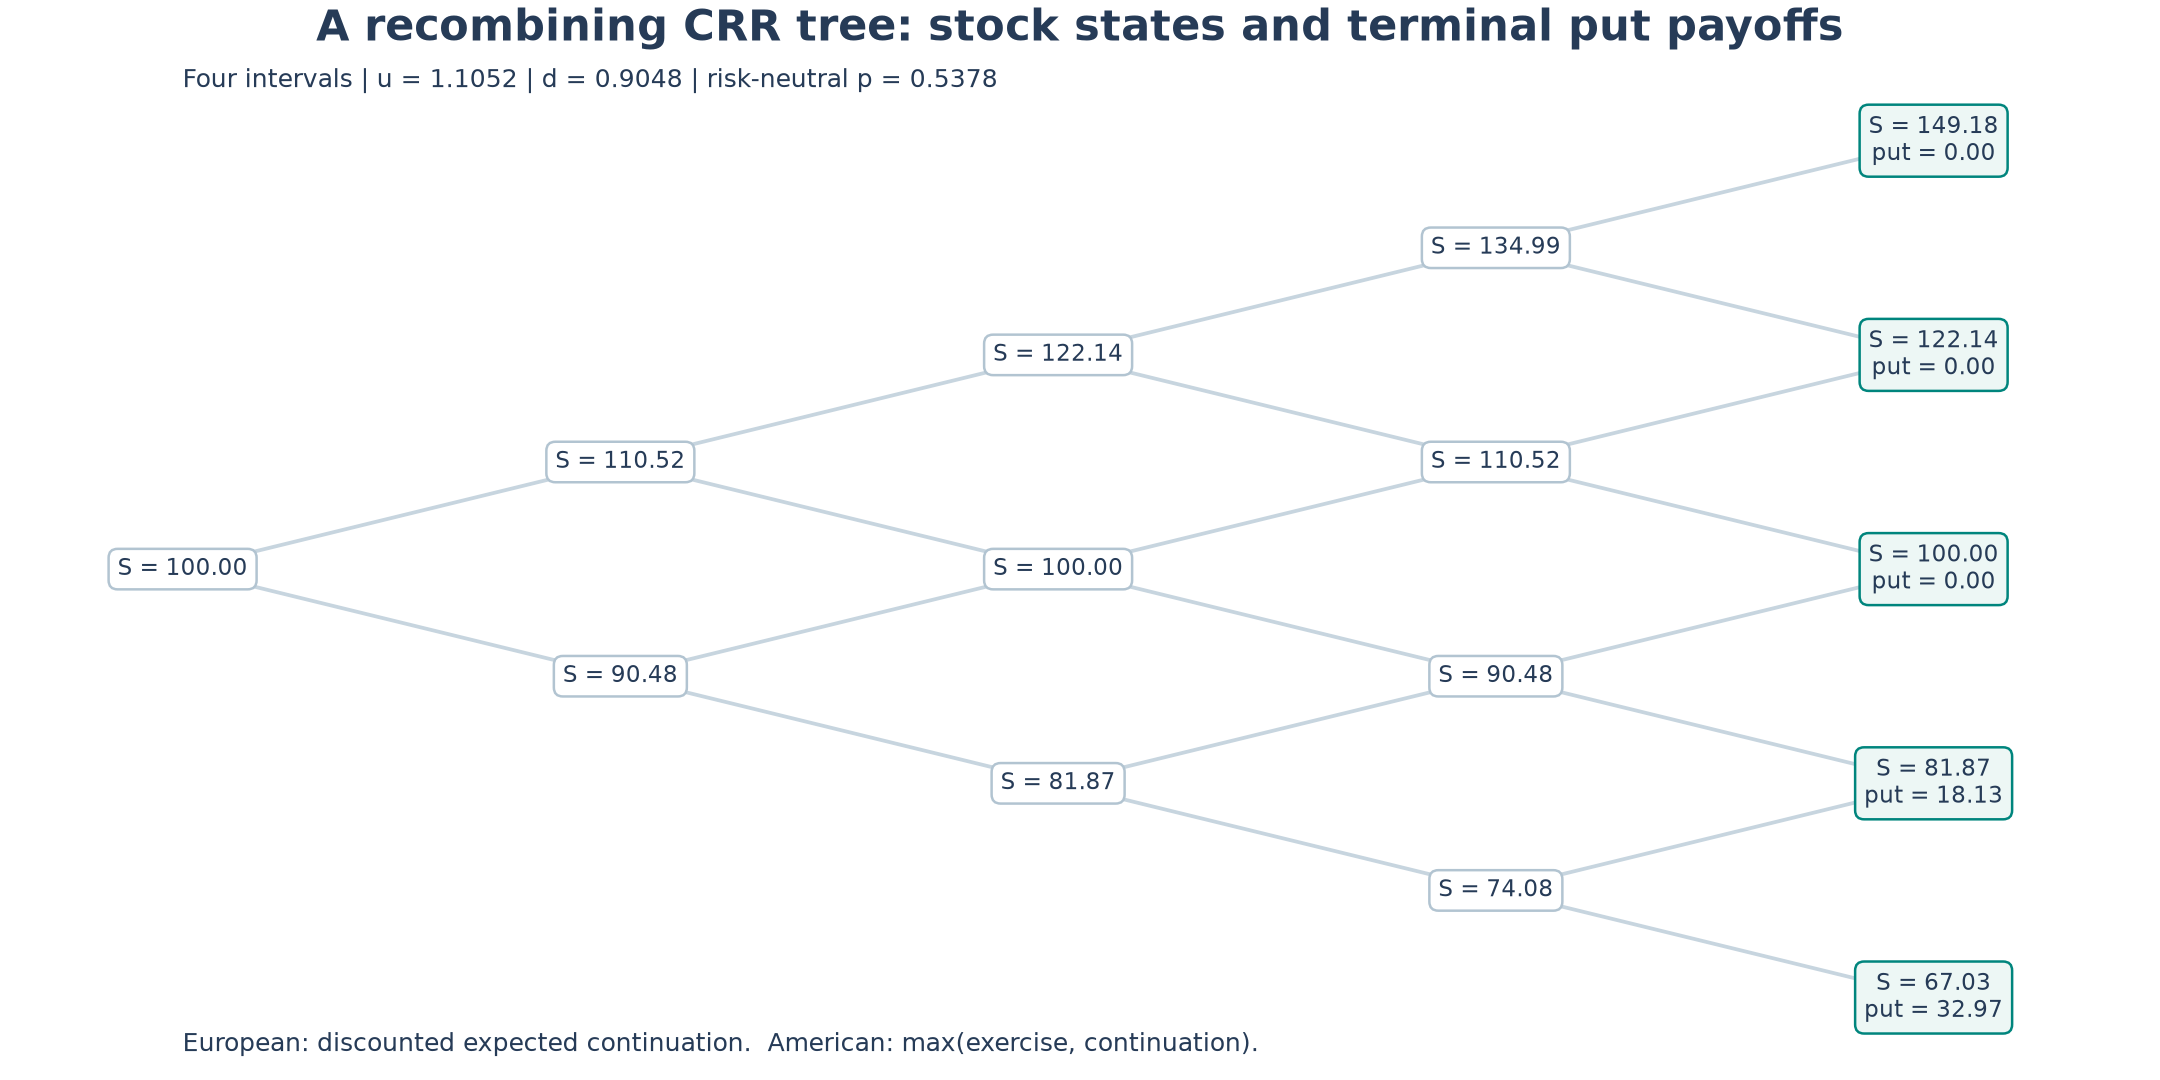

,method,option_type,steps,price,benchmark,absolute_error
12,binomial_european,call,800,10.448084,10.450584,0.002499
13,binomial_american,call,800,10.448084,10.449584,0.001499
26,binomial_european,put,800,5.571027,5.573526,0.002499
27,binomial_american,put,800,6.089402,6.089990,0.000588


In [2]:
display(Image(filename=str(ROOT / 'figures' / 'binomial_tree.png')))
tree = frames['tree_convergence']
display(tree[tree.steps == tree.steps.max()][
    ['method', 'option_type', 'steps', 'price', 'benchmark', 'absolute_error']].round(6))

## 2. Sampling error and policy error are different

European Monte Carlo samples the exact GBM terminal distribution. Its discounted-payoff mean has
estimated standard error $s/\sqrt{N}$; there is no time-stepping bias for this terminal payoff.
The pointwise asymptotic 95% interval is the estimate plus or minus $1.96$ standard errors.
Individual paths of estimates need not improve monotonically as $N$ grows.

The American baseline defaults to exercising an in-the-money put at $S_t\leq0.85K$.
The illustrated comparison deliberately sets the boundary to $0.75K$ to expose policy bias.
This feasible policy has expected value below or equal to the optimal American value. More paths
shrink its sampling error while leaving policy bias. LSM learns a more flexible stopping rule.
For non-dividend calls at nonnegative rates, both American MC programs hold until maturity.

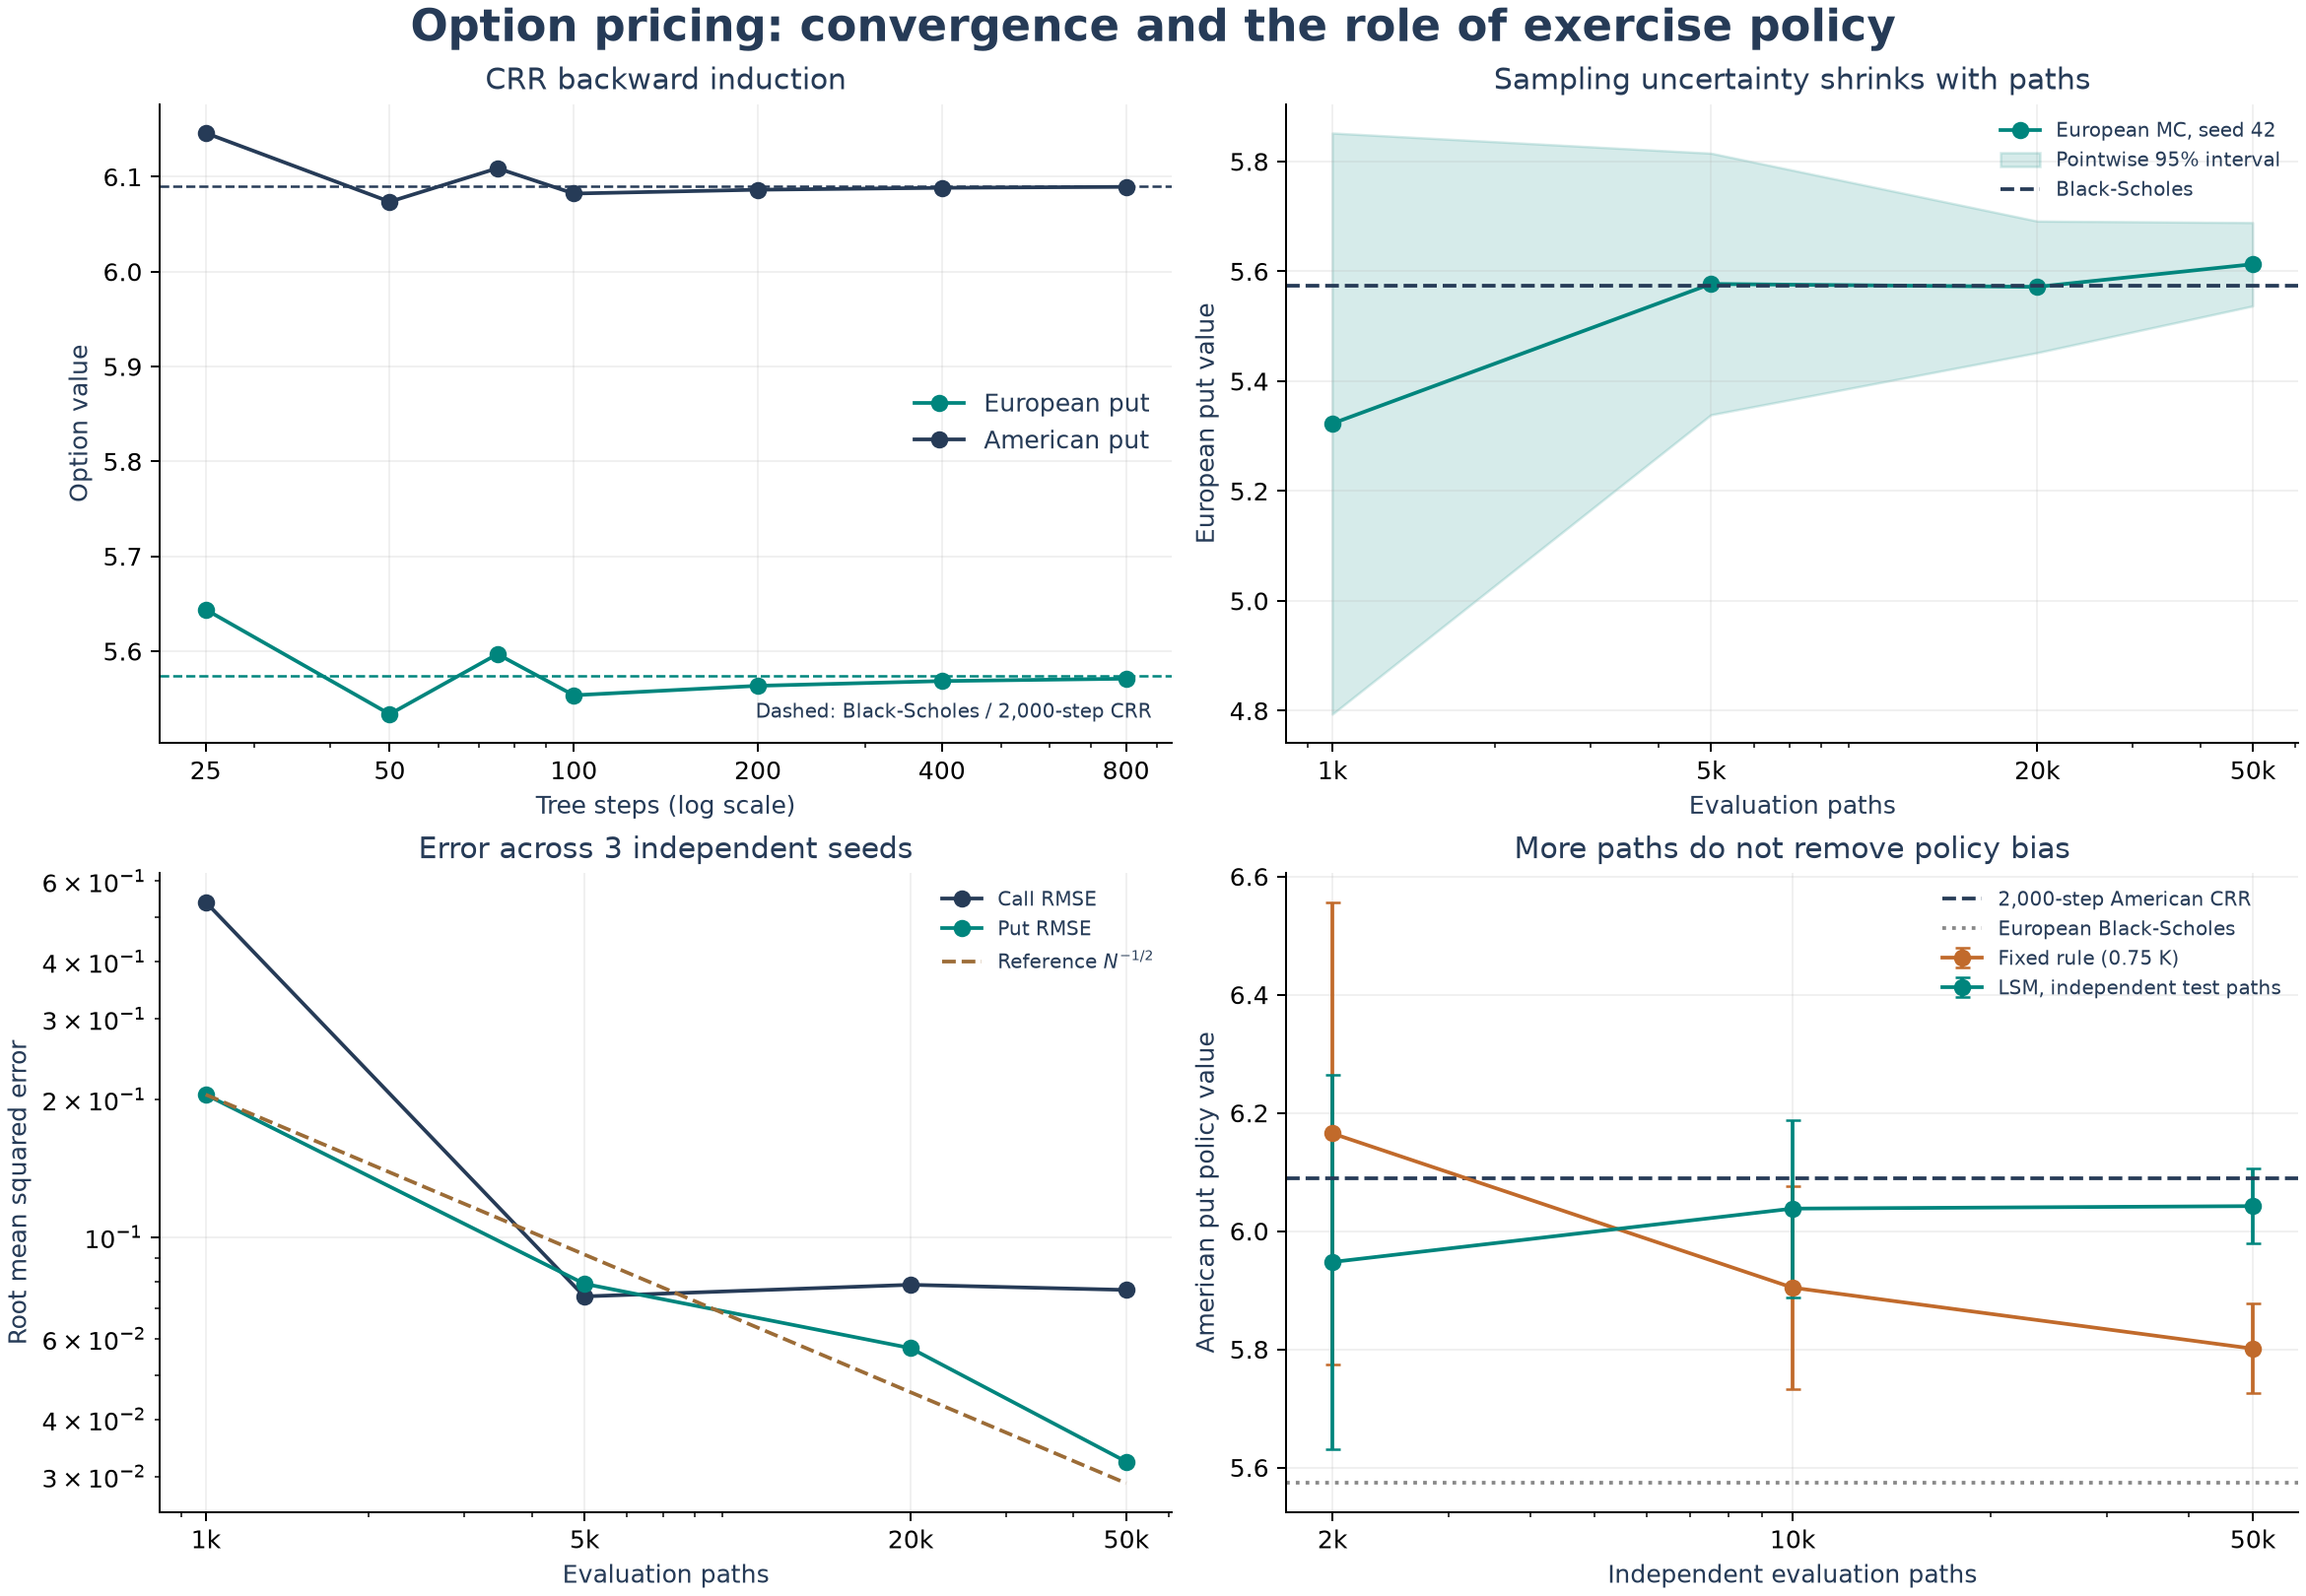

rmse  average_reported_se  seeds
option_type paths                                      
call        1000   0.540279             0.465255      3
            5000   0.074211             0.208054      3
            20000  0.078685             0.103838      3
            50000  0.076680             0.065915      3
put         1000   0.204954             0.271551      3
            5000   0.079084             0.122739      3
            20000  0.057224             0.061635      3
            50000  0.032321             0.038783      3

In [3]:
display(Image(filename=str(ROOT / 'figures' / 'convergence.png')))
mc = frames['mc_convergence'].copy()
mc['squared_error'] = (mc.price - mc.benchmark) ** 2
summary = mc.groupby(['option_type', 'paths']).agg(
    rmse=('squared_error', lambda values: np.sqrt(values.mean())),
    average_reported_se=('standard_error', 'mean'),
    seeds=('seed', 'nunique'))
display(summary.round(6))

## 3. Three European variance reduction techniques

- **Antithetic:** average payoffs from $Z$ and $-Z$. With $N$ payoff evaluations,
  only $N/2$ pair averages are independent; use those averages for standard errors.
- **Control variate:** adjust by discounted $S_T$, whose expectation is $S_0$.
  Estimate the coefficient on an independent pilot, whose extra cost is recorded.
- **Importance sampling:** use the original basic Newton updates on the pilot second moment,
  obtain an approximate Gaussian shift, and plug it into likelihood-weighted valuation.
  Both fitted methods use 2,000 additional pilot paths in the benchmark comparisons.

Main-sample budgets match. The figures also include pilot work. A variance reduction factor is
plain-MC estimator variance divided by the method's estimator variance. The work-adjusted factor
also accounts for terminal payoff counts; those counts are a cost proxy, not a CPU-time guarantee.

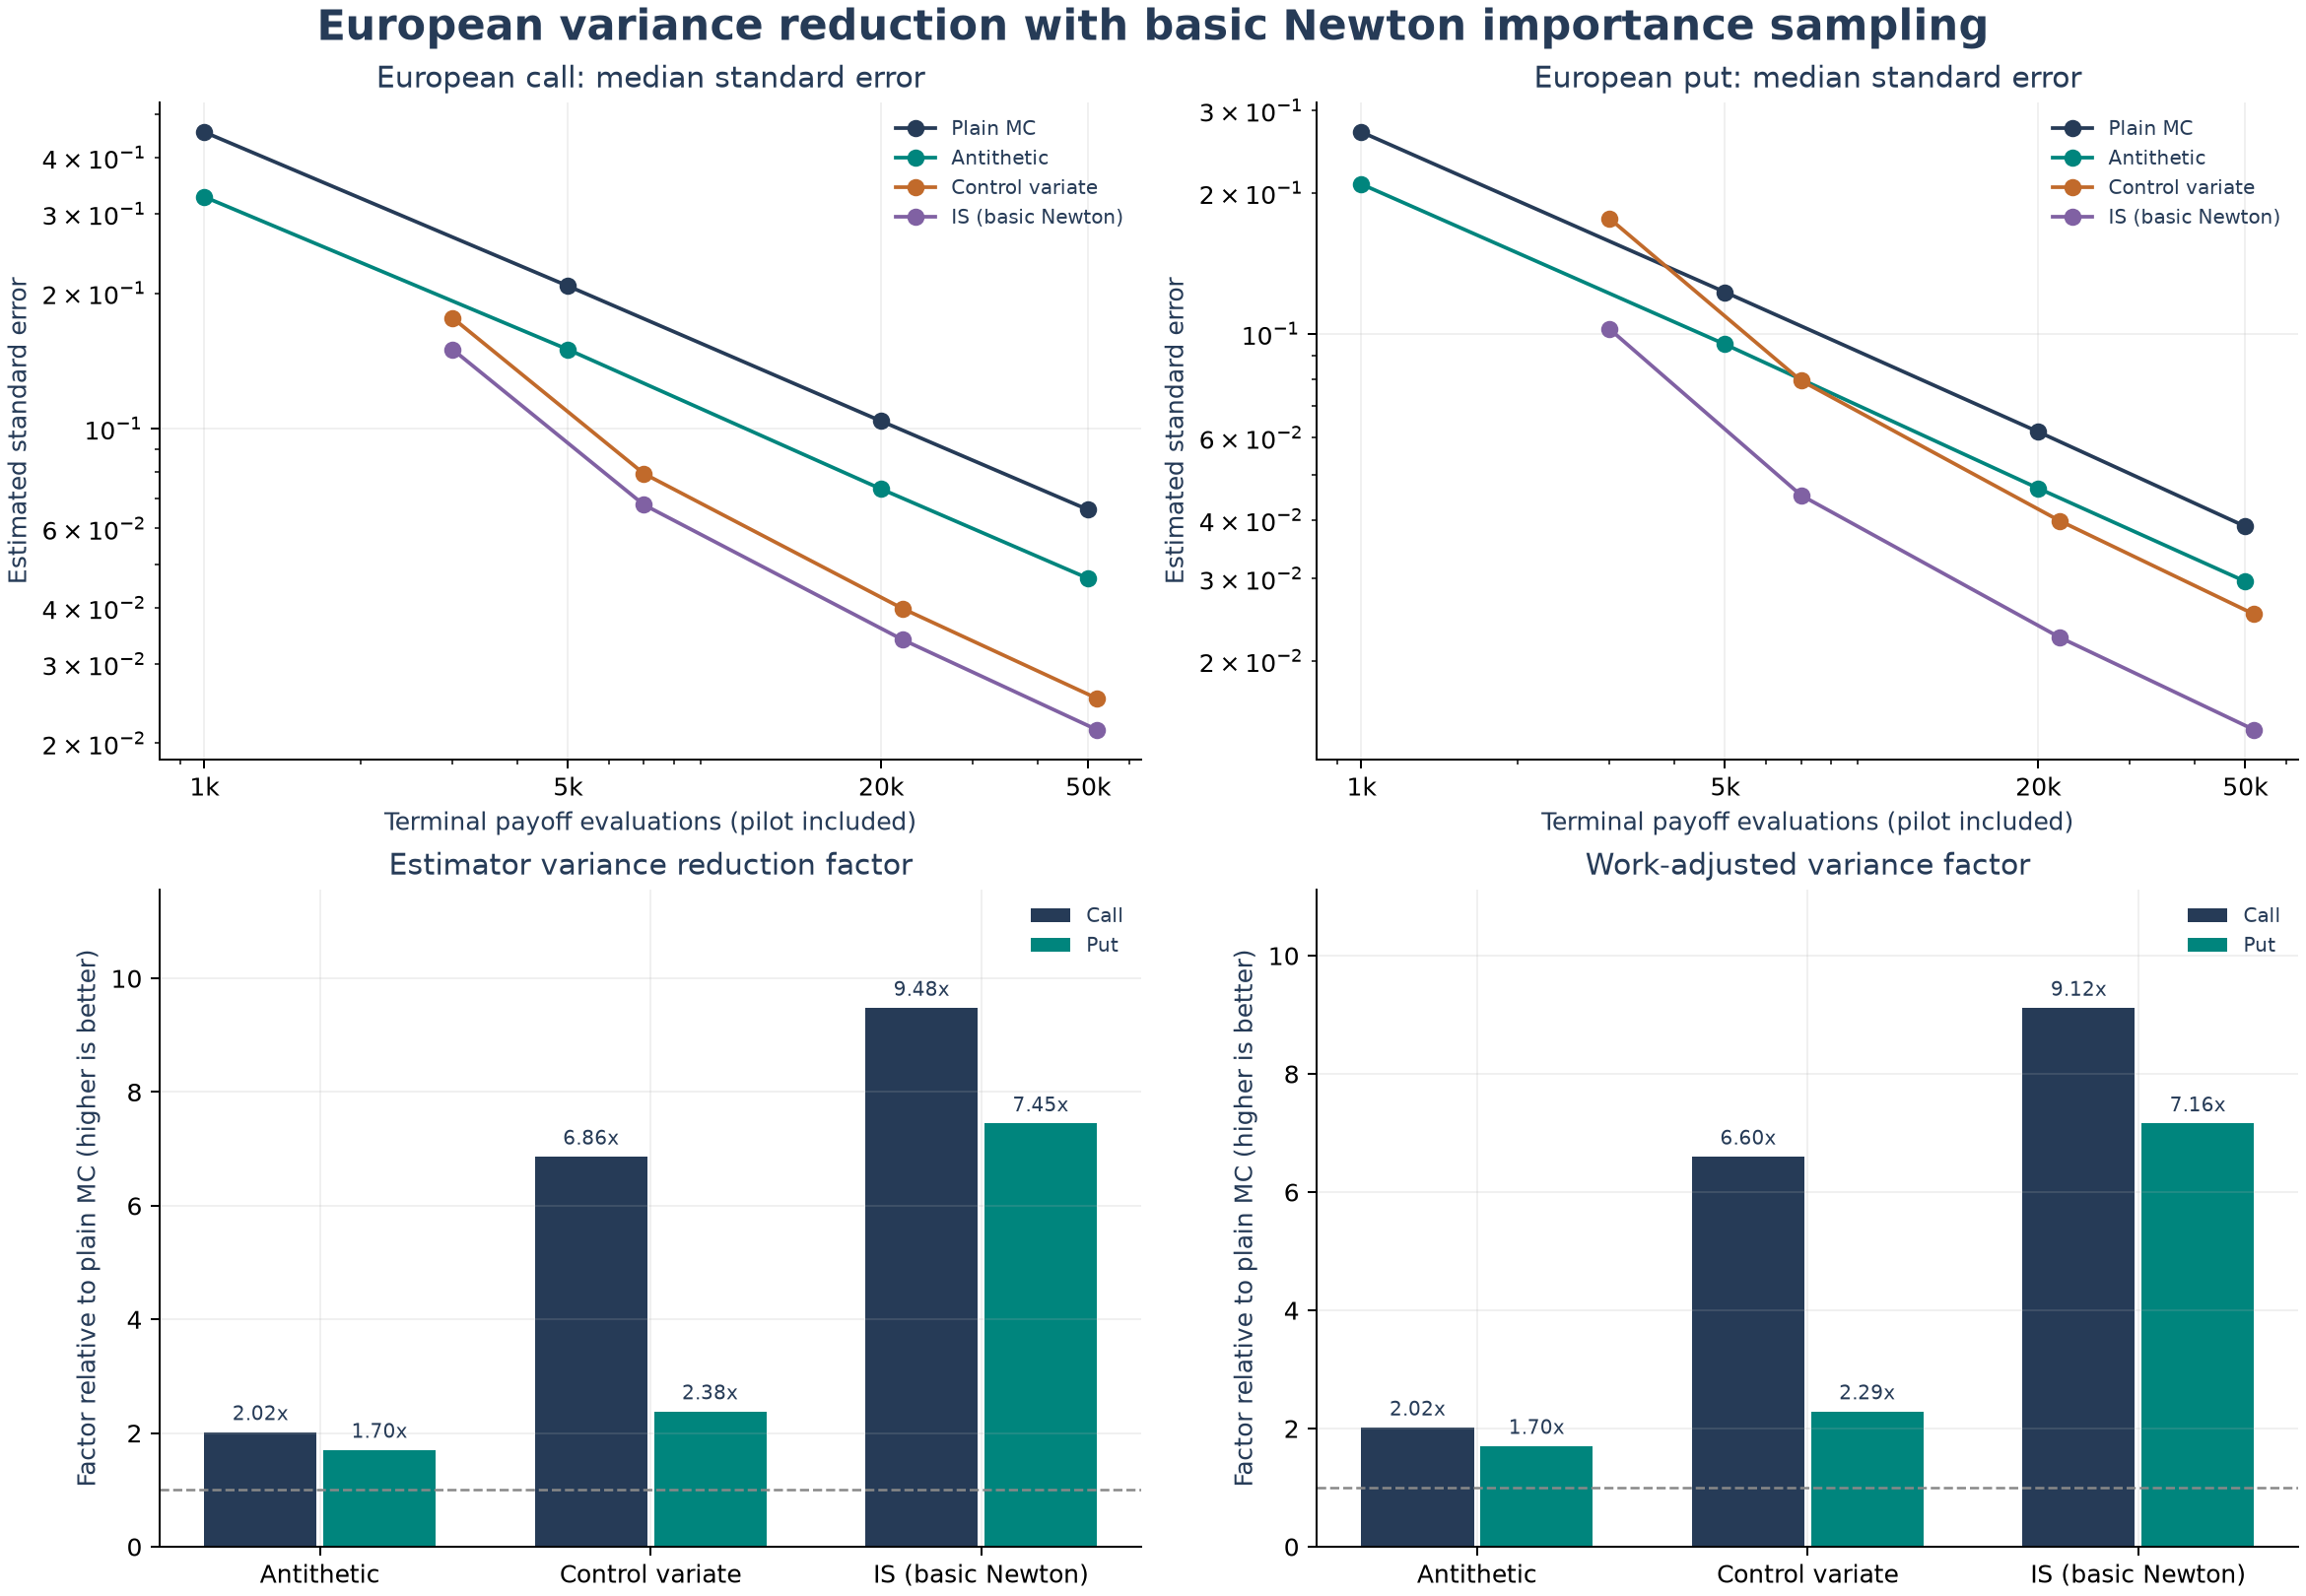

,option_type,method,price,standard_error,independent_samples,training_paths,payoff_evaluations,control_beta,importance_shift
36,call,plain_mc,10.346369,0.065497,50000,0,50000,0.000000,0.000000
37,call,antithetic,10.408664,0.046129,25000,0,50000,0.000000,0.000000
38,call,control_variate,10.442808,0.025066,50000,2000,52000,0.671632,0.000000
39,call,importance_sampling,10.456328,0.021432,50000,2000,52000,0.000000,1.128042
84,put,plain_mc,5.612900,0.038771,50000,0,50000,0.000000,0.000000
85,put,antithetic,5.550330,0.029481,25000,0,50000,0.000000,0.000000
86,put,control_variate,5.565750,0.025066,50000,2000,52000,-0.328368,0.000000
87,put,importance_sampling,5.582092,0.014166,50000,2000,52000,0.000000,-1.197987


In [4]:
display(Image(filename=str(ROOT / 'figures' / 'variance_reduction.png')))
vr = frames['variance_reduction']
largest = vr[(vr.paths == vr.paths.max()) & (vr.seed == 42)]
display(largest[['option_type', 'method', 'price', 'standard_error',
                 'independent_samples', 'training_paths', 'payoff_evaluations',
                 'control_beta', 'importance_shift']].round(6))

### Basic Newton procedure: approximate the shift, then plug it in

For fixed pilot draws, calculate
$\widehat M(\mu)=m^{-1}\sum_i h(z_i)^2e^{\mu^2/2-\mu z_i}$ and its
first two derivatives. Apply the original update
$\mu_{k+1}=\mu_k-\operatorname{clip}(\widehat M'/\widehat M'',-1,1)$.

Initialize at the standardized exercise threshold: its positive part
for calls, or negative part for puts. Stop when either the absolute
derivative or the absolute shift change is below $10^{-8}$, with a
maximum of 50 updates. Fix the approximate shift before independent
pricing. The figure shows the direct objective and both stopping checks.

Both pilot generation and fitting count toward runtime. The pilot is
counted once in payoff evaluations; Newton scans reuse stored payoffs.
All-zero pilots fail explicitly. The mathematical derivation in the
methodology follows the direct second-moment procedure above.

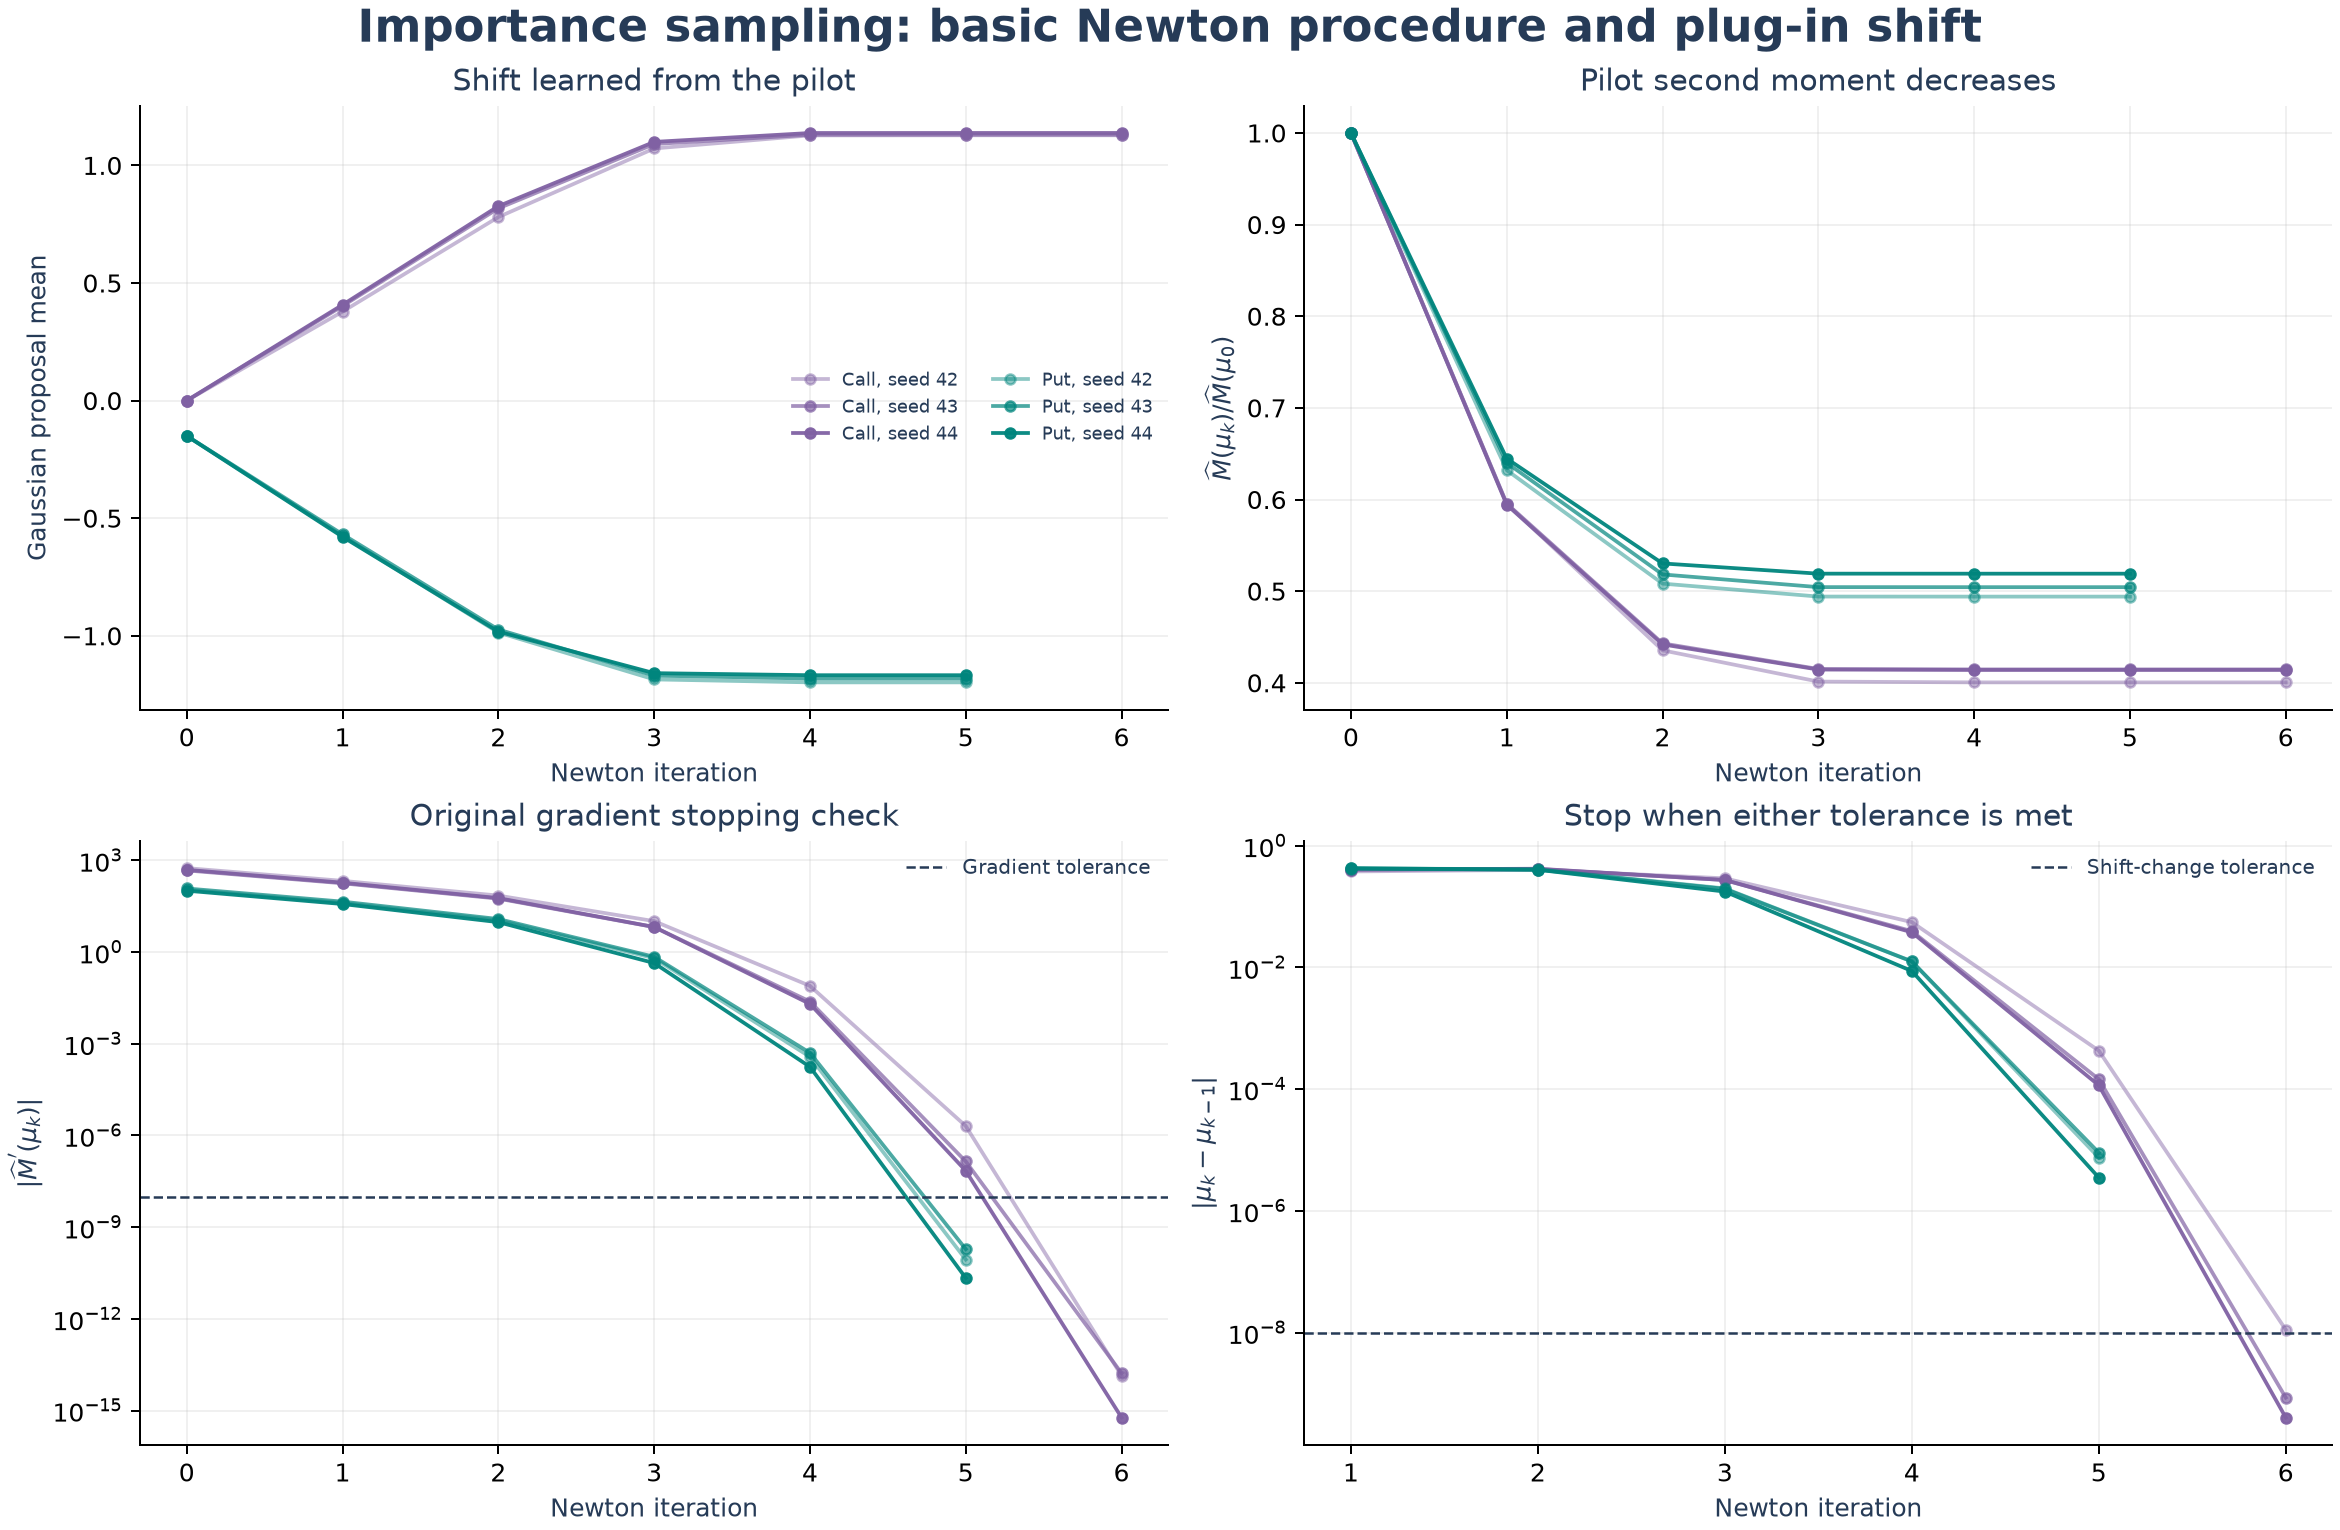

,option_type,seed,training_paths,iteration,shift,gradient,status
6,call,42,2000,6,1.128042,-0.000000e+00,converged_gradient
13,call,43,2000,6,1.130516,-0.000000e+00,converged_step
20,call,44,2000,6,1.137907,0.000000e+00,converged_step
26,put,42,2000,5,-1.197987,1.000000e-10,converged_gradient
32,put,43,2000,5,-1.181844,2.000000e-10,converged_gradient
38,put,44,2000,5,-1.167525,0.000000e+00,converged_gradient


,option_type,method,paths,seeds,training_paths,median_variance_reduction_pct,median_work_adjusted_factor
0,call,antithetic,50000,3,0,50.3977,2.0160
1,call,control_variate,50000,3,2000,85.4321,6.6004
2,call,importance_sampling,50000,3,2000,89.4530,9.1167
3,put,antithetic,50000,3,0,41.3134,1.7040
4,put,control_variate,50000,3,2000,57.9984,2.2893
5,put,importance_sampling,50000,3,2000,86.5729,7.1612


In [5]:
display(Image(filename=str(ROOT / 'figures' / 'newton_convergence.png')))
trace = frames['newton_convergence']
final_fits = trace.groupby(['option_type', 'seed'], sort=False).tail(1)
display(final_fits[['option_type', 'seed', 'training_paths', 'iteration',
                    'shift', 'gradient', 'status']].round(10))
display(frames['variance_summary'][['option_type', 'method', 'paths', 'seeds',
    'training_paths', 'median_variance_reduction_pct', 'median_work_adjusted_factor']].round(4))

## 4. Longstaff–Schwartz with independent evaluation

The training pass regresses discounted future cashflows on $1,x,x^2$ using in-the-money paths,
where $x=S_t/K$. Centering/scaling and QR improve numerical stability; degenerate regressions
fall back to lower-degree or constant fits. The time-zero decision uses training data too.

The policy is frozen, then evaluated forward on a separate random stream. Its confidence
interval quantifies evaluation noise conditional on that policy. It excludes retraining
variability, regression bias, exercise-grid bias, and tree reference error.
The 2,000-step American CRR reference has a different state and exercise grid from the MC policy.

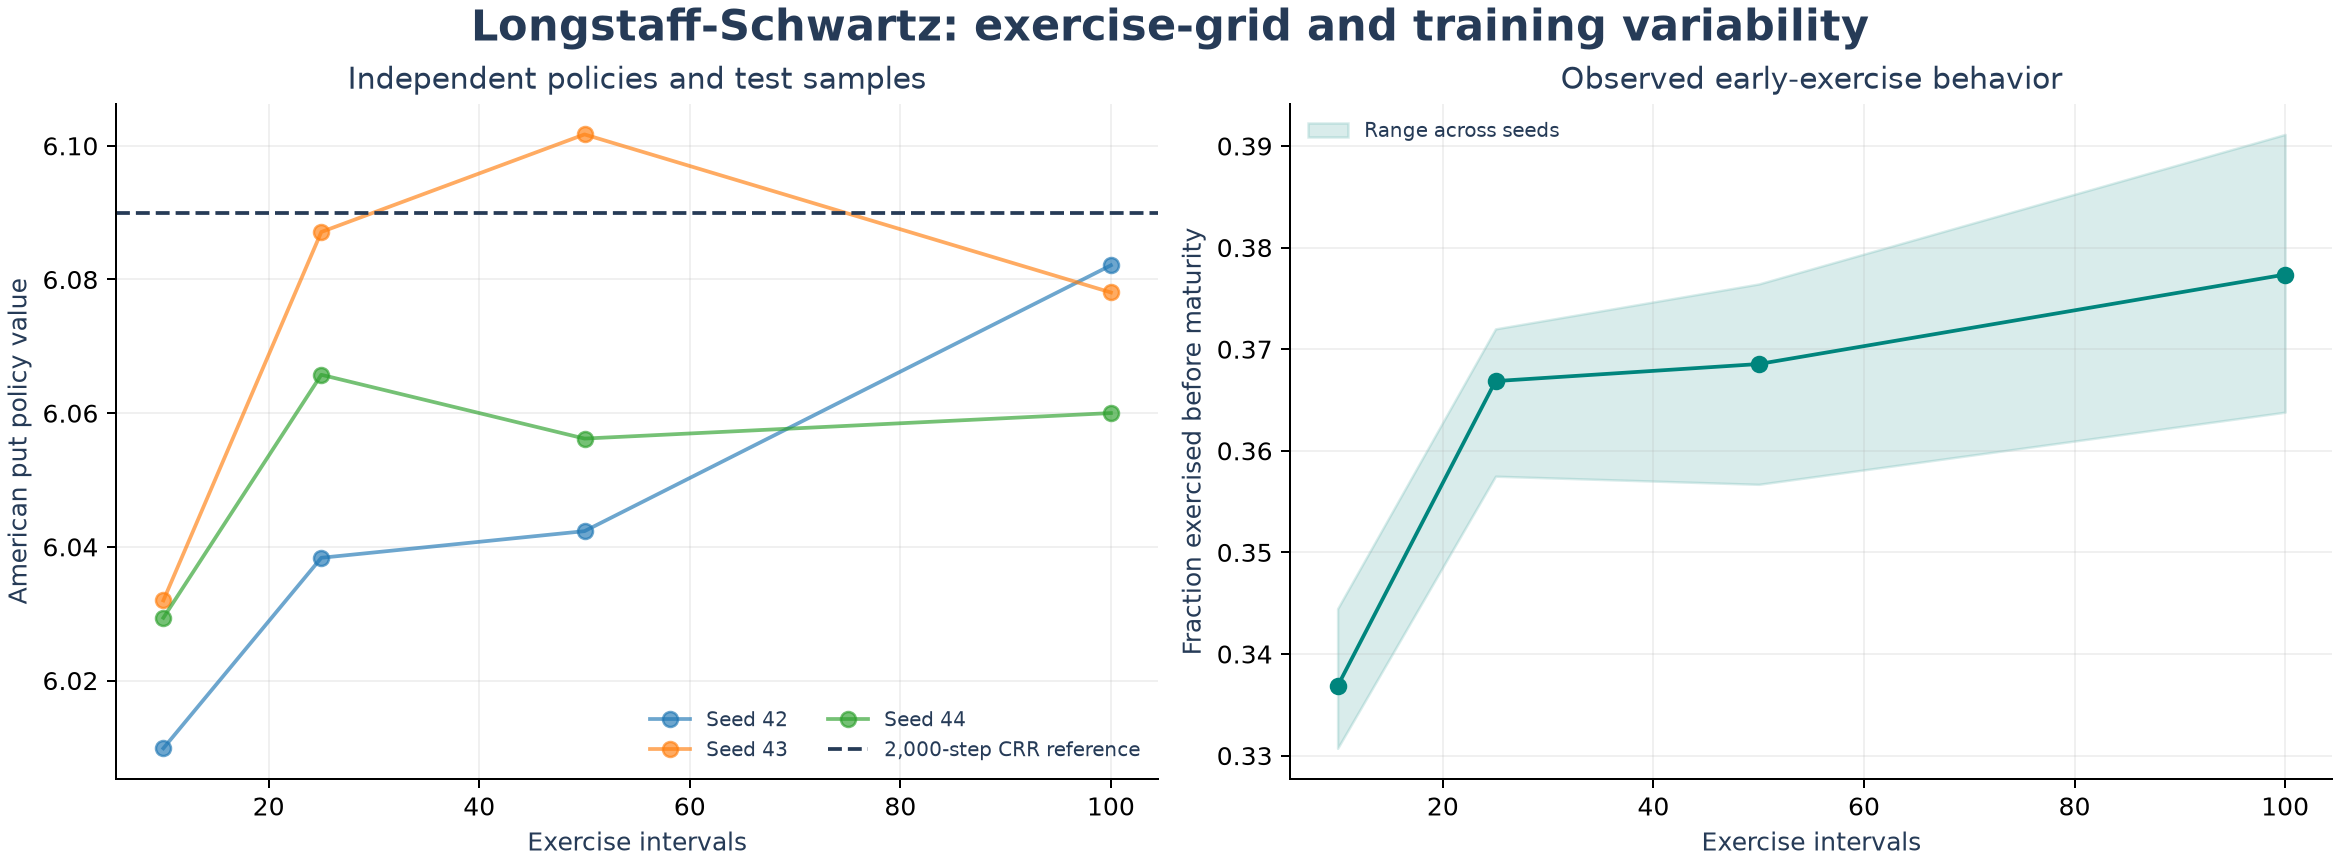

,average_price,between_seed_sd,average_evaluation_se,tree_reference,average_early_exercise_fraction
method,,,,,
lsm_american,6.066750,0.031053,0.032482,6.08999,0.368540
monte_carlo_american_fixed_policy,5.761967,0.050884,0.038598,6.08999,0.099913


In [6]:
display(Image(filename=str(ROOT / 'figures' / 'lsm_exercise_grid.png')))
american = frames['american_convergence']
final = american[american.paths == american.paths.max()]
display(final.groupby('method').agg(
    average_price=('price', 'mean'),
    between_seed_sd=('price', 'std'),
    average_evaluation_se=('standard_error', 'mean'),
    tree_reference=('benchmark', 'first'),
    average_early_exercise_fraction=('exercise_fraction', 'mean')).round(6))

## 5. Explore a contract by calling C++ directly

Edit the parameters below and rerun the cell. Select any of the six executable names in the README.
`variance_reduction` returns plain MC and all three variance reduction methods in one call.
Tree/LSM methods use `steps`; European MC samples one exact terminal draw per path.

In [7]:
method = 'variance_reduction'
parameters = dict(type='call', spot=90, strike=100, rate=0.05,
                  volatility=0.20, maturity=1, paths=100000,
                  train_paths=5000, steps=50, seed=42)
custom = pd.DataFrame(run(method, ROOT / 'build', **parameters))
numeric_columns = [name for name in custom.columns if name not in ['method', 'option_type', 'newton_status']]
custom[numeric_columns] = custom[numeric_columns].apply(pd.to_numeric)
display(custom[['method', 'price', 'standard_error', 'ci_lower', 'ci_upper',
                'benchmark', 'payoff_evaluations']].round(6))

,method,price,standard_error,ci_lower,ci_upper,benchmark,payoff_evaluations
0,plain_mc,5.021176,0.031922,4.958610,5.083743,5.091222,100000
1,antithetic,5.072850,0.027719,5.018523,5.127178,5.091222,100000
2,control_variate,5.078161,0.017400,5.044058,5.112264,5.091222,105000
3,importance_sampling,5.086771,0.009303,5.068538,5.105004,5.091222,105000


## Interpretation and next experiments

Read each interval as uncertainty about the relevant estimator's expectation, rather than as a
complete error bound on the model price. Fixed policies retain exercise-policy bias; LSM also
retains regression and exercise-grid error. More seeds and separate training/evaluation sweeps
are needed before making precise claims about convergence rates or empirical coverage.

Useful extensions are a larger moneyness/volatility/maturity grid, basis-degree comparisons,
more training seeds, matched-date Bermudan tree references, and a dual upper-bound method.
These are proposed extensions, not implemented results.

See [methodology](../docs/methodology.md) for equations, accounting conventions, and primary references.